In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 69.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.8.93
    Uninstalling nvidia-nvjitlink-cu12-12.8.93:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.8.93
  Attempting uninstall: nvidia-curand-cu12
    Found existing installation: nvidia-curand-cu12 10.3.9.90
    Uninstalling nvidia-curand-cu12-10.3.9

In [2]:
import os
from glob import glob
from tqdm.notebook import tqdm
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
import random
import torch
import shutil
from pathlib import Path
from tqdm.auto import tqdm
import yaml

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
!cp -r /kaggle/input/rasoul-binary-aabb/dataset /kaggle/working/

In [4]:
# Set the seed value
SEED = 42  

# Python’s built-in random module
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Ensure deterministic behavior in PyTorch
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Set PYTHONHASHSEED to ensure consistent behavior in hash-based operations
os.environ["PYTHONHASHSEED"] = str(SEED)

In [5]:
# --- 1. SETUP AND PATH DEFINITIONS ---
# --- MODIFIED: Using pathlib.Path to prevent AttributeErrors ---
dataset_yaml_path = Path("/kaggle/working/dataset.yaml")
weights_dir = Path('/kaggle/input/yolo-binary-detection-weights/B-AABBWeights')
threshold_csv_path = '/kaggle/input/c-threshold-for-rasoul-b-detection/data_outputs/model_performance_summary.csv' 
output_dir_data = Path("/kaggle/working/data_outputs")
output_dir_plots = Path("/kaggle/working/myplots")
output_dir_final_runs = Path("/kaggle/working/optimal_runs")

# Create all necessary output directories
os.makedirs(output_dir_data, exist_ok=True)
os.makedirs(output_dir_plots, exist_ok=True)
os.makedirs(output_dir_final_runs, exist_ok=True)
os.makedirs(output_dir_plots / "ConfMats", exist_ok=True)

In [6]:
# Generating yaml file
# Define YOLO dataset structure
data = {
    'train': '/kaggle/working/dataset/images/train',
    'val': '/kaggle/working/dataset/images/val',
    'test': '/kaggle/working/dataset/images/test',
    'nc': 1,  # Number of classes
    'names': ['ICH']  # Class names
}

# Save YAML file
with open(dataset_yaml_path, 'w') as file:
    yaml.dump(data, file, default_flow_style=False)

print(f"YAML file saved at: {dataset_yaml_path}")

YAML file saved at: /kaggle/working/dataset.yaml


In [7]:
def organize_confusion_matrices(source_dir: Path, dest_dir: Path):
    """
    Finds confusion matrices in subdirectories, renames them by their parent
    folder's name, and copies them to a destination folder.
    """
    # 1. Create the destination folder if it doesn't exist
    dest_dir.mkdir(parents=True, exist_ok=True)
    
    # 2. Find all 'confusion_matrix.png' files within the source subdirectories
    source_files = list(source_dir.glob('*/confusion_matrix.png'))
    
    if not source_files:
        print(f"⚠️ Warning: No 'confusion_matrix.png' files found under '{source_dir}'")
        return

    print(f"Found {len(source_files)} confusion matrices. Copying to '{dest_dir}'...")
    
    # 3. Loop through the files with a progress bar, copy, and rename
    for source_path in tqdm(source_files, desc="Copying Matrices"):
        try:
            # Extract the model name from the parent directory's name
            model_name = source_path.parent.name
            
            # Define the new path for the copied file
            dest_path = dest_dir / f"{model_name}_confusion_matrix.png"
            
            # Copy the file
            shutil.copy(source_path, dest_path)
            
        except Exception as e:
            print(f"❌ Error processing {source_path.name}: {e}")

    print(f"\n✅ Copying complete.")

In [8]:
# Load the optimal thresholds from the tuning script
try:
    threshold_df = pd.read_csv(threshold_csv_path)
    threshold_map = dict(zip(threshold_df['model'], threshold_df['best_threshold']))
except FileNotFoundError:
    print(f"Error: Threshold CSV not found at {threshold_csv_path}. Script will stop.")
    exit() # Stop if the crucial threshold file is missing

In [9]:
# --- 2. FINAL INFERENCE AND EVALUATION LOOP ---
# --- CORRECTED: Initialized loop variables ---
output_results = []
model_paths = list(weights_dir.glob('*.pt'))
pbar = tqdm(model_paths, desc="Processing models")

for model_path in pbar:
    model_name = model_path.stem
    pbar.set_description(f"Processing {model_name}")

    conf_threshold = threshold_map[model_name] # Using direct access as requested
    model = YOLO(model_path)

    # Run val() ONCE to get metrics AND save .txt files and plots
    metrics = model.val(
        data=str(dataset_yaml_path),
        split='test',
        conf=conf_threshold,
        iou=0.5,
        save_txt=True,
        save_conf=True,
        plots=True,
        project='/kaggle/working/inference_runs',
        name=model_name,
        exist_ok=True,
        verbose=False,
        seed=SEED,
        device=0
    )

    output_results.append({
        'model': model_name,
        'threshold': conf_threshold,
        'f1': metrics.box.f1[0],
        'precision': metrics.box.p[0],
        'recall': metrics.box.r[0],
        'mAP@0.5': metrics.box.map50,
        'mAP@0.5:0.95': metrics.box.map
    })

pbar.close()

Processing models:   0%|          | 0/9 [00:00<?, ?it/s]

Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 925.3±552.2 MB/s, size: 32.9 KB)
val: Scanning /kaggle/working/dataset/labels/test... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 1.5Kit/s 1.6s
val: New cache created: /kaggle/working/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 2.8it/s 53.6s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       2429        815      0.765       0.55      0.685      0.452
Speed: 0.3ms preprocess, 20.0ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolov8m
Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 812.0±602.2 MB/s, size: 35.6 KB)
val: Scanning /kaggle/working/dataset/labels/test.cache... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 3.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 8.2it/s 18.6s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


...

                   all       2429        815      0.766      0.562      0.695      0.451
Speed: 0.4ms preprocess, 9.7ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolov8s
Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12s summary (fused): 159 layers, 9,231,267 parameters, 0 gradients, 21.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 824.3±744.3 MB/s, size: 32.6 KB)
val: Scanning /kaggle/working/dataset/labels/test.cache... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 3.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 3.7it/s 41.4s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       2429        815      0.743      0.562      0.635      0.374
Speed: 0.4ms preprocess, 15.0ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolo12s
Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1212.2±536.9 MB/s, size: 38.3 KB)
val: Scanning /kaggle/working/dataset/labels/test.cache... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 4.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 10.9it/s 13.9s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       2429        815       0.75      0.536      0.673      0.441
Speed: 0.4ms preprocess, 3.9ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolov8n



--- Test Set Performance ---
     model  threshold        f1  precision    recall   mAP@0.5  mAP@0.5:0.95
0  yolov8m       0.40  0.639684   0.764908  0.549693  0.685364      0.452333
1  yolo12n       0.05  0.635882   0.770970  0.541076  0.654726      0.403208
2  yolo11n       0.65  0.640057   0.763605  0.550920  0.683976      0.452106
3  yolo12m       0.50  0.612314   0.703034  0.542331  0.651094      0.405442
4  yolo11s       0.75  0.636896   0.789474  0.533742  0.678909      0.436754
5  yolo11m       0.60  0.632203   0.780443  0.531288  0.679427      0.440040
6  yolov8s       0.50  0.648266   0.765886  0.561963  0.694943      0.450559
7  yolo12s       0.05  0.639912   0.742968  0.561963  0.634728      0.373877
8  yolov8n       0.25  0.625387   0.750170  0.536196  0.672860      0.440844


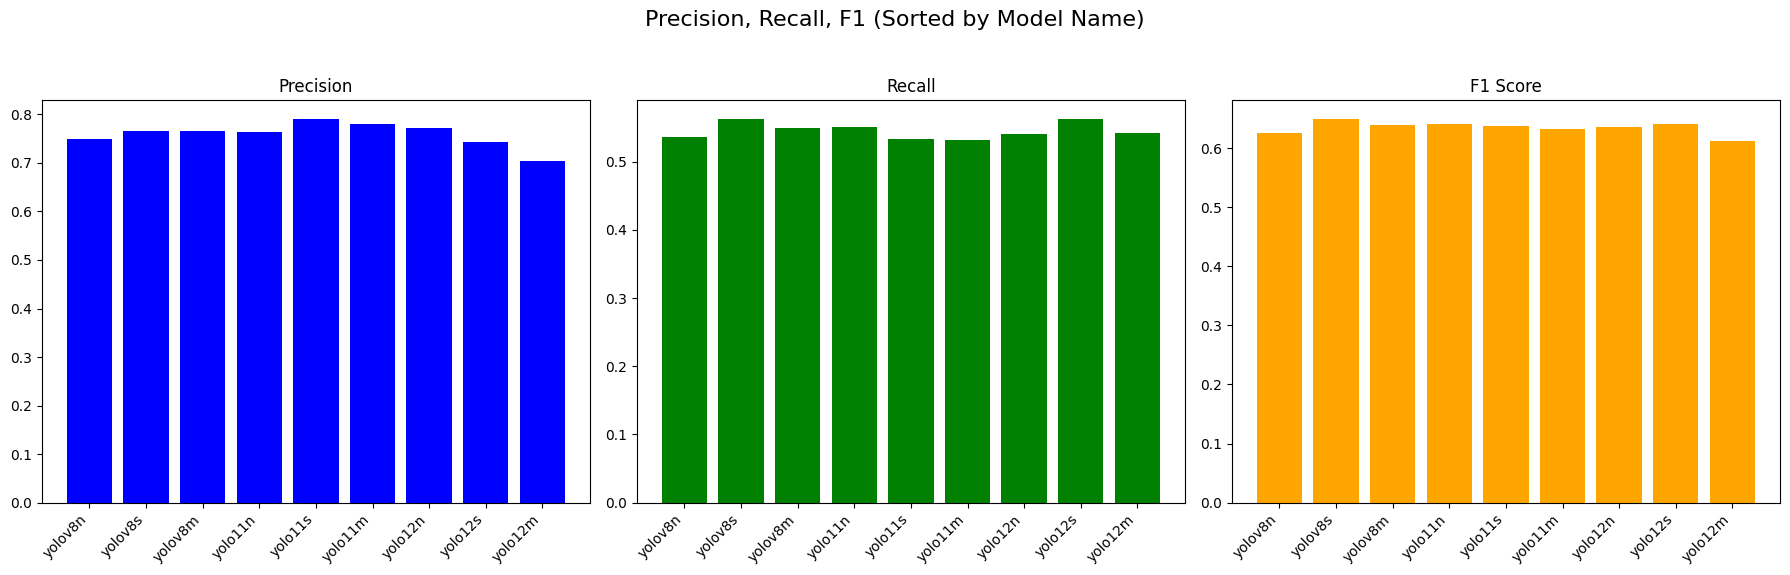

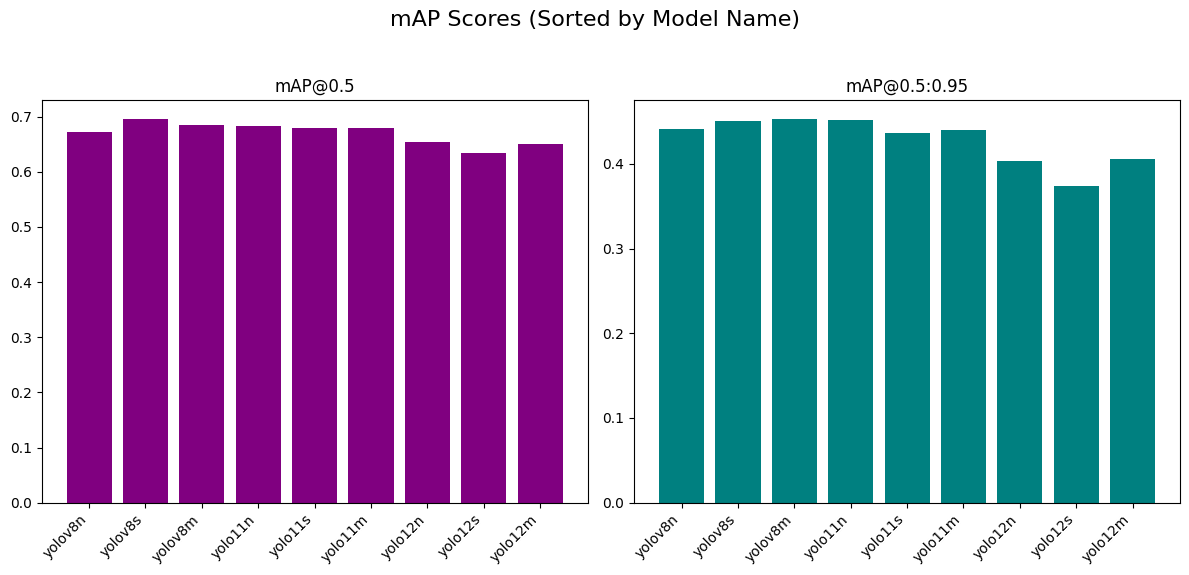

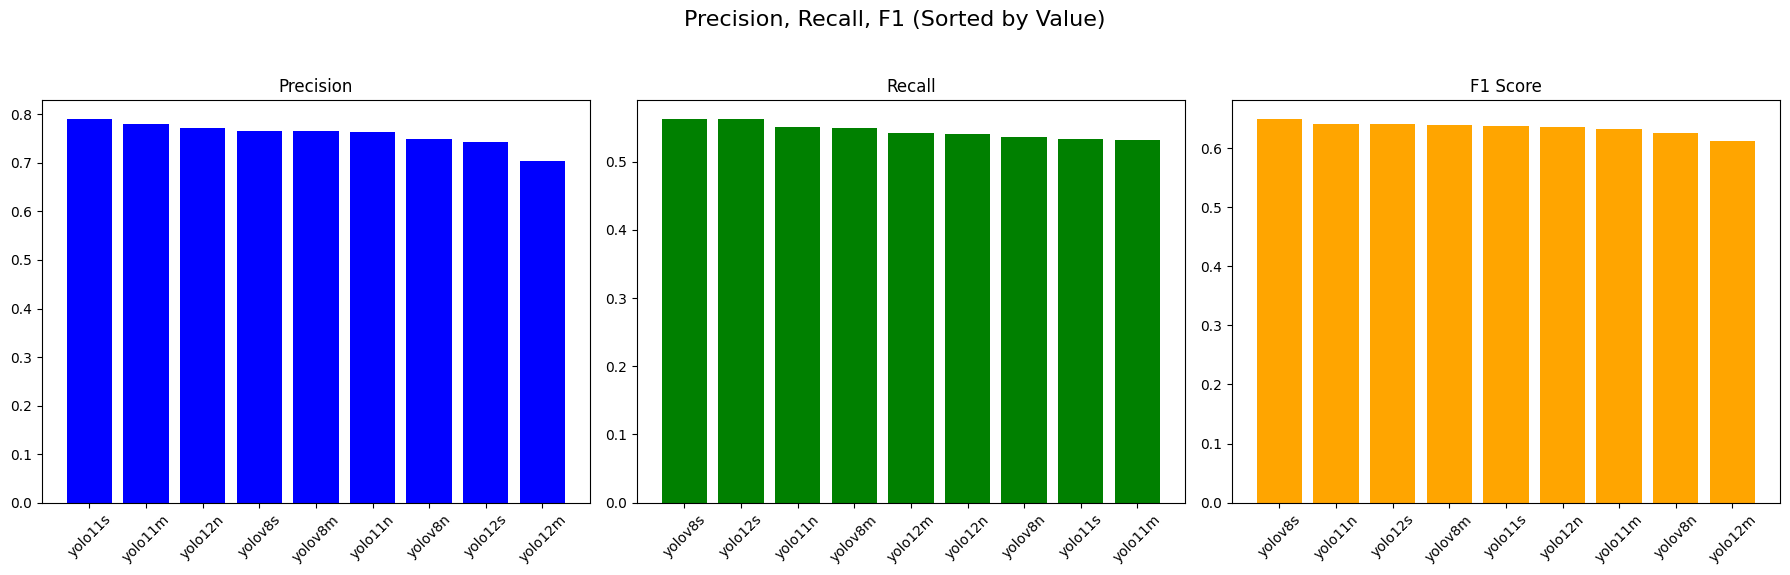

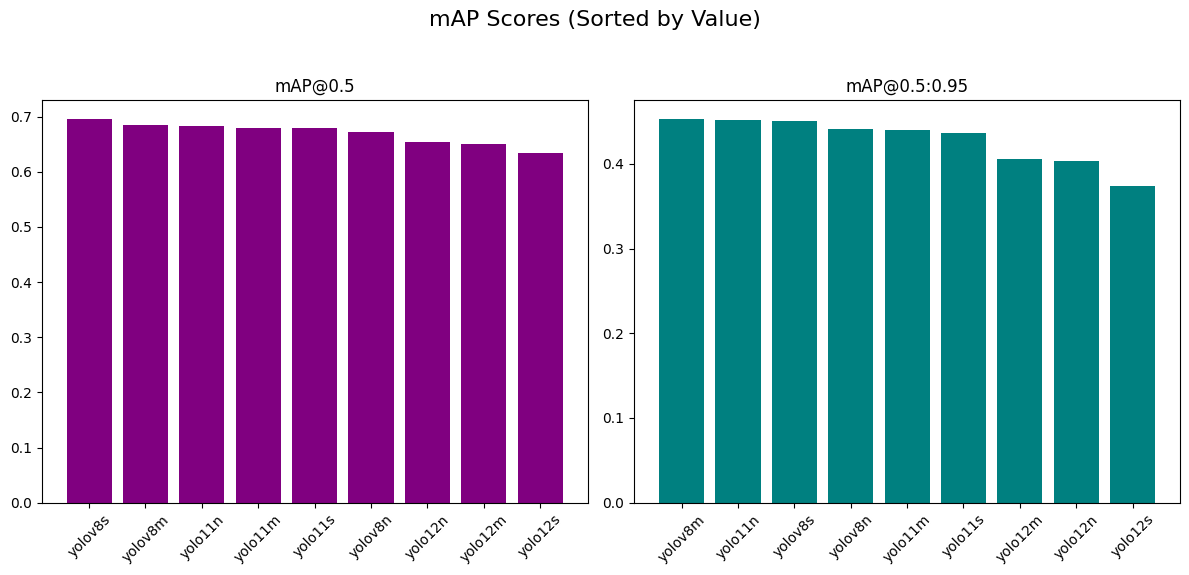

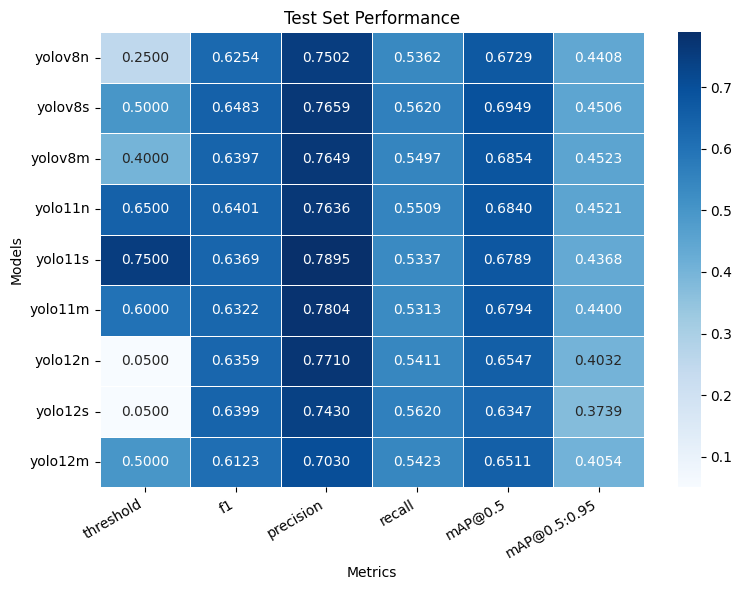


--- Organizing final confusion matrices ---
Found 9 confusion matrices. Copying to '/kaggle/working/myplots/ConfMats'...


Copying Matrices:   0%|          | 0/9 [00:00<?, ?it/s]


✅ Copying complete.

✅ All tasks complete.


In [10]:
# --- 3. CORRECTED REPORTING AND PLOTTING SECTION ---
if not output_results:
    print("No results were generated. Exiting.")
else:
    # Creates the DataFrame from the correct 'output_results' list
    df_results = pd.DataFrame(output_results)
    df_results.to_csv(output_dir_data / 'output_results_test_metrics.csv', index=False)
    
    print("\n--- Test Set Performance ---")
    print(df_results)

    models_order = ["yolov8n", "yolov8s", "yolov8m",
                    "yolo11n", "yolo11s", "yolo11m",
                    "yolo12n", "yolo12s", "yolo12m"]
    
    df_results['model'] = pd.Categorical(df_results['model'], categories=models_order, ordered=True)
    df_ordered = df_results.sort_values('model')

    # --- Plots Sorted by Model Name ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Precision, Recall, F1 (Sorted by Model Name)', fontsize=16)
    x = np.arange(len(df_ordered))
    
    axes[0].bar(x, df_ordered['precision'], color='blue')
    axes[0].set_title('Precision')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    axes[1].bar(x, df_ordered['recall'], color='green')
    axes[1].set_title('Recall')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    axes[2].bar(x, df_ordered['f1'], color='orange')
    axes[2].set_title('F1 Score')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "PRF_byName.png")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle('mAP Scores (Sorted by Model Name)', fontsize=16)
    
    axes[0].bar(x, df_ordered['mAP@0.5'], color='purple')
    axes[0].set_title('mAP@0.5')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    axes[1].bar(x, df_ordered['mAP@0.5:0.95'], color='teal')
    axes[1].set_title('mAP@0.5:0.95')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "mAP_byName.png")
    plt.show()
    
    # --- Plots Sorted by Metric Value ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Precision, Recall, F1 (Sorted by Value)', fontsize=16)
    
    df_p = df_ordered.sort_values(by='precision', ascending=False)
    axes[0].bar(df_p['model'], df_p['precision'], color='blue')
    axes[0].set_title('Precision')
    axes[0].tick_params(axis='x', rotation=45)
    
    df_r = df_ordered.sort_values(by='recall', ascending=False)
    axes[1].bar(df_r['model'], df_r['recall'], color='green')
    axes[1].set_title('Recall')
    axes[1].tick_params(axis='x', rotation=45)
    
    df_f = df_ordered.sort_values(by='f1', ascending=False)
    axes[2].bar(df_f['model'], df_f['f1'], color='orange')
    axes[2].set_title('F1 Score')
    axes[2].tick_params(axis='x', rotation=45)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "PRF_byValue.png")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle('mAP Scores (Sorted by Value)', fontsize=16)
    
    df_m50 = df_ordered.sort_values(by='mAP@0.5', ascending=False)
    axes[0].bar(df_m50['model'], df_m50['mAP@0.5'], color='purple')
    axes[0].set_title('mAP@0.5')
    axes[0].tick_params(axis='x', rotation=45)
    
    df_m95 = df_ordered.sort_values(by='mAP@0.5:0.95', ascending=False)
    axes[1].bar(df_m95['model'], df_m95['mAP@0.5:0.95'], color='teal')
    axes[1].set_title('mAP@0.5:0.95')
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "mAP_byValue.png")
    plt.show()

    # --- Heatmap ---
    # MODIFIED: Removed .drop(['threshold'], axis=1) to include it in the plot
    df_heatmap = df_ordered.set_index('model')
    plt.figure(figsize=(8, 6)) # Increased figsize to better fit the new column
    sns.heatmap(df_heatmap, annot=True, fmt=".4f", cmap="Blues", linewidths=.5, cbar=True)
    plt.title("Test Set Performance")
    plt.xlabel("Metrics")
    plt.ylabel("Models")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(output_dir_plots / "Metrics_Heatmap.png")
    plt.show()
    
    # --- Call the function to organize the confusion matrices ---
    print("\n--- Organizing final confusion matrices ---")
    source_directory_for_cms = Path("/kaggle/working/inference_runs")
    destination_directory_for_cms = output_dir_plots / "ConfMats"
    organize_confusion_matrices(source_directory_for_cms, destination_directory_for_cms)

    print("\n✅ All tasks complete.")

In [11]:
!rm -rf /kaggle/working/dataset